# 한 프레임의 검출에서 시간에 걸친 ID까지

영상은 `(H,W,C)` 이미지가 시간 순서대로 들어오는 흐름이다. 목표는 **배경 상태 → 전경 마스크 →
박스·중심점 → 거리 행렬 → 짝짓기 → ID·기억 갱신 → 평가**를 따라가고 앱의 성공·실패를 설명하는 것이다.
Python 기본 변수·반복문에서 출발해 첫 실제 프레임 계산을 펼친 뒤 기존 클래스를 재사용한다.
등록 물체 특징점 매칭은 사람의 ID 추적과 별도 기능으로 배운다. 기본 흐름 뒤에 보너스를 둔다.

A3-2에서 `uv sync --group dev` 후 `.venv` Python을 노트북 커널로 선택한다.
위에서 아래로 실행하며 기존 `outputs`와 입력 영상은 수정하지 않는다.
`uv run --group dev python tools/build_learning_notebook.py --execute`는 새 커널로 전체 재생성·실행한다.
test 영상 5개 전체의 검출과 특징점 실험을 다시 계산하므로 수 분이 걸릴 수 있다.

[기존 HTML](../study/a3-2.html)은 시간 재생·설정 비교용, 이 노트북은 실제 Python 배열과 객체 상태 확인용이다.
합성 영상 결과는 실제 사람 영상의 성능을 대표하지 않는다.

In [1]:
from pathlib import Path
import sys
import json
import platform
from dataclasses import replace
import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
assert (root/'src/tracker.py').is_file(), 'A3-2 또는 notebooks에서 실행하세요.'
sys.path.insert(0,str(root))
from src import motion, tracker, evaluate, experiments, synthetic, features, cache
from src.hungarian import gated_assignment
from src.pipeline import VideoAnalyzer
from src.image_io import imread
cache.configure(None)  # 디스크 캐시 대신 현재 입력과 코드로 계산한다.
cv2.setNumThreads(2)
np.set_printoptions(precision=3,suppress=True)
print('Python',platform.python_version(),'OpenCV',cv2.__version__,'NumPy',np.__version__)

def table(headers,rows):
    lines=[' | '.join(headers),' | '.join(['---']*len(headers))]
    for row in rows:
        lines.append(' | '.join(str(value) for value in row))
    display(Markdown('\n'.join(lines)))

def show_images(items,columns=3):
    rows=(len(items)+columns-1)//columns
    fig,axes=plt.subplots(rows,columns,figsize=(4*columns,3*rows),squeeze=False)
    for axis in axes.flat:
        axis.axis('off')
    for axis,(name,image) in zip(axes.flat,items):
        if image.ndim==3:
            image=cv2.cvtColor(image,cv2.COLOR_BGR2RGB)
        axis.imshow(image,cmap='gray',vmin=0,vmax=255)
        axis.set_title(name)
    fig.tight_layout()
    display(fig)
    plt.close(fig)

def array_table(items):
    rows=[]
    for name,image in items:
        rows.append([name,image.shape,image.dtype,int(image.min()),int(image.max())])
    table(['배열','shape','dtype','최소','최대'],rows)

def snapshot(tracks):
    # Track 객체는 다음 update에서 바뀐다. 값을 복사해 그 시점의 기록을 남긴다.
    rows=[]
    for track in tracks:
        trail=list(track.trail)
        rows.append([track.id,tuple(track.centroid),track.missed,track.hits,track.age,len(trail),trail[-5:]])
    return rows

saved=json.loads((root/'outputs/results.json').read_text(encoding='utf-8'))

Python 3.12.13 OpenCV 5.0.0 NumPy 2.5.4


## 1. 시간 순서와 배경 상태

같은 프레임도 **앞에 어떤 프레임을 처리했는지**에 따라 전경 마스크가 달라진다.
매 프레임마다 `MotionDetector()`를 새로 만들면 배경 학습이 사라진다. 영상 첫 30프레임은 빈 배경이다.
프레임 번호는 0부터 센다. 합성 영상은 640×360, 30fps이며 f70은 약 2.33초다.
색 배열은 BGR `uint8`, 값 범위는 0~255다. 좌표는 `(x,y)`, 픽셀 접근은 `[y,x]`다.

앱 기본은 MOG2다. 한 픽셀을 여러 가우시안으로 표현하는 내부 상태를 가진다.
아래 작은 예는 원리를 수치로 따라가기 위한 **별도 이동평균 모델**이며 MOG2의 내부 구현과 같지 않다.
현재 프레임과 **갱신 전** 배경을 비교하고, 그 다음 `bg += α*(frame-bg)`로 갱신한다.

In [2]:
tiny_background=np.full((2,2,3),50,np.uint8)
tiny_frame=tiny_background.copy()
tiny_frame[0,0]=150
alpha=0.25
old_background=tiny_background.astype(np.float32)
difference=np.abs(tiny_frame.astype(np.float32)-old_background).max(axis=2)
manual_mask=np.where(difference>25,255,0).astype(np.uint8)
updated_background=old_background+alpha*(tiny_frame.astype(np.float32)-old_background)
running=motion.RunningAverageSubtractor(threshold=25)
running.apply(tiny_background,alpha)
actual_mask=running.apply(tiny_frame,alpha)
print('채널별 차이 중 최대:\n',difference,'\n마스크:\n',manual_mask)
print('한 픽셀 배경: 50 + 0.25*(150-50) =',updated_background[0,0])
np.testing.assert_array_equal(manual_mask,actual_mask)
np.testing.assert_array_equal(updated_background,running.bg)
# 동일한 밝기 150이 반복되면 배경으로 흡수된다. α=0이면 이 상태를 유지한다.
print('반복 관측 시 남는 밝기 차이:',[round(100*(1-alpha)**n,2) for n in [0,1,5,10]])

채널별 차이 중 최대:
 [[100.   0.]
 [  0.   0.]] 
마스크:
 [[255   0]
 [  0   0]]
한 픽셀 배경: 50 + 0.25*(150-50) = [75. 75. 75.]
반복 관측 시 남는 밝기 차이: [100.0, 75.0, 23.73, 5.63]


## 2. 실제 crossing_test의 f70: 전처리와 전경

먼저 f0~f69를 순서대로 먹여 같은 배경 상태를 만든다. 임의 시점으로 점프해 f70만 넣는 것과 다르다.
MOG2 원본 마스크는 보통 0=배경, 127=그림자, 255=전경이다. `raw>200`으로 그림자를 제거한다.
첫 프레임이 거의 전부 전경이어도 곧바로 사람 검출 성능으로 해석하지 않는다.

배열 | shape | dtype | 최소 | 최대
--- | --- | --- | --- | ---
frame f70 | (360, 640, 3) | uint8 | 5 | 220
blurred | (360, 640, 3) | uint8 | 10 | 219
raw MOG2 | (360, 640) | uint8 | 0 | 255
foreground | (360, 640) | uint8 | 0 | 255

raw 고유 값: [  0 127 255] 그림자 픽셀: 1873


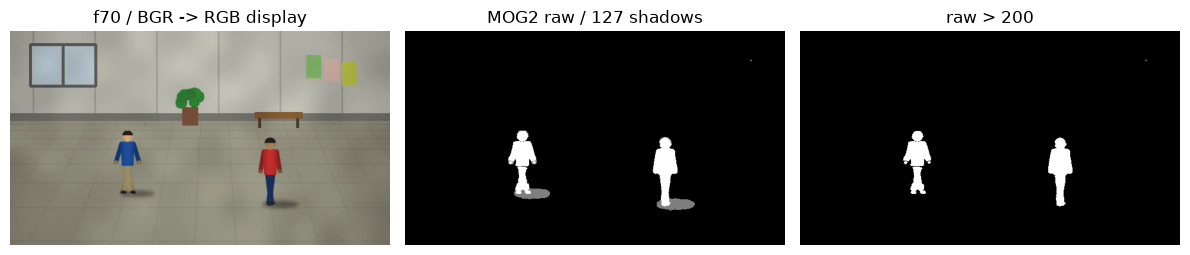

In [3]:
params=motion.MotionParams()
assert vars(params)==saved['params']['motion']
video=root/'data/synthetic/crossing_test.mp4'
subtractor=motion.make_subtractor(params)
module_detector=motion.MotionDetector(replace(params))
stream=evaluate.read_frames(video)
previous_detections=None
try:
    for frame_index in range(71):
        frame=next(stream)
        if frame_index<70:
            motion.foreground_mask(subtractor,frame,params)
            previous_detections,_,_=module_detector(frame)
finally:
    stream.close()
blurred=cv2.GaussianBlur(frame,(params.blur,params.blur),0)
raw=subtractor.apply(blurred,learningRate=params.learning_rate)
foreground=np.where(raw>200,255,0).astype(np.uint8)
module_detections,module_clean,module_raw=module_detector(frame)
np.testing.assert_array_equal(raw,module_raw)
array_table([('frame f70',frame),('blurred',blurred),('raw MOG2',raw),('foreground',foreground)])
print('raw 고유 값:',np.unique(raw),'그림자 픽셀:',np.count_nonzero(raw==127))
show_images([('f70 / BGR -> RGB display',frame),('MOG2 raw / 127 shadows',raw),('raw > 200',foreground)])

## 3. 모폴로지 → 윤곽선 → 박스·중심점

열림(침식→팽창)은 작은 점을 지우고, 닫힘(팽창→침식)은 몸의 틈을 잇는다.
닫힘을 너무 크게 하면 두 사람도 한 덩어리가 된다. 여기서는 3×3·11×11 타원 커널을 쓴다.
윤곽선 하나는 `(N,1,2)` 좌표 배열, 검출 결과는 `Detection` 객체들의 리스트다.
`area`는 윤곽선 면적이므로 박스의 `w*h`와 다르다. 중심은 무게중심이 아니라 **박스 중심**이다.

윤곽선 점 수 | 면적 px² | 박스 x,y,w,h | 면적 통과
--- | --- | --- | ---
80 | 2537.5 | (418, 179, 41, 116) | True
107 | 2505.0 | (174, 168, 47, 106) | True

검출 번호 (ID 아님) | 박스 | 중심 (x,y)
--- | --- | ---
0 | (418, 179, 41, 116) | (438.5, 237.0)
1 | (174, 168, 47, 106) | (197.5, 221.0)

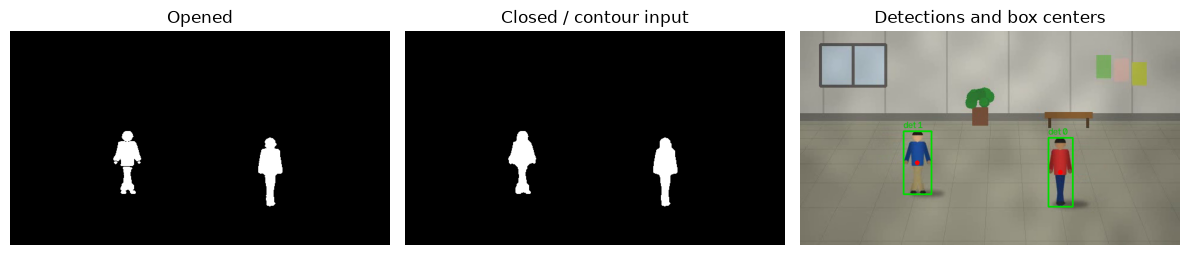

In [4]:
open_kernel=cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(params.open_ksize,params.open_ksize))
close_kernel=cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(params.close_ksize,params.close_ksize))
opened=cv2.morphologyEx(foreground,cv2.MORPH_OPEN,open_kernel)
cleaned=cv2.morphologyEx(opened,cv2.MORPH_CLOSE,close_kernel)
contours,_=cv2.findContours(cleaned,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
detections=[]
candidate_rows=[]
for contour in contours:
    area=cv2.contourArea(contour)
    x,y,w,h=cv2.boundingRect(contour)
    accepted=area>=params.min_area
    candidate_rows.append([len(contour),round(area,1),(x,y,w,h),accepted])
    if accepted:
        center=(x+w/2.0,y+h/2.0)
        detections.append(motion.Detection((x,y,w,h),center,float(area)))
table(['윤곽선 점 수','면적 px²','박스 x,y,w,h','면적 통과'],candidate_rows)
np.testing.assert_array_equal(cleaned,module_clean)
assert [(d.bbox,d.centroid,d.area) for d in detections]==[(d.bbox,d.centroid,d.area) for d in module_detections]
overlay=frame.copy()
for number,detection in enumerate(detections):
    x,y,w,h=detection.bbox
    cv2.rectangle(overlay,(x,y),(x+w,y+h),(0,220,0),2)
    cx,cy=detection.centroid
    cv2.circle(overlay,(int(cx),int(cy)),4,(0,0,255),-1)
    cv2.putText(overlay,f'det {number}',(x,y-5),cv2.FONT_HERSHEY_SIMPLEX,0.5,(0,200,0),1)
table(['검출 번호 (ID 아님)','박스','중심 (x,y)'],[(i,d.bbox,d.centroid) for i,d in enumerate(detections)])
show_images([('Opened',opened),('Closed / contour input',cleaned),('Detections and box centers',overlay)])

## 4. 두 프레임을 잇기: 거리 행렬과 탐욕 할당

첫 추적기에는 f69 검출을 넣어 ID를 만든다. 다음 f70에서는 행=기존 Track, 열=현재 Detection이다.
기본 추적기는 마지막 중심점에 머문다고 가정한다. `predicted`도 이 위치이고, 속도 예측은 보너스 칼만에서만 한다.
거리 `sqrt(dx²+dy²)`를 `max_distance=60px`로 나눈 값이 비용이다. 비용 1보다 크면 짝지을 수 없다.
가장 작은 유효 비용부터 행·열을 한 번씩만 사용한다. 검출 번호는 매 프레임 바뀌므로 ID로 쓰지 않는다.

In [5]:
tracker_object=tracker.Tracker()
tracker_object.update(previous_detections)
before=snapshot(tracker_object.tracks.values())
old_tracks=list(tracker_object.tracks.values())
costs=np.zeros((len(old_tracks),len(detections)),dtype=float)
for row,old in enumerate(old_tracks):
    old.predicted=old.centroid
    for column,new in enumerate(detections):
        dx=old.centroid[0]-new.centroid[0]
        dy=old.centroid[1]-new.centroid[1]
        costs[row,column]=np.sqrt(dx*dx+dy*dy)/tracker_object.max_distance
print('거리 px:\n',costs*tracker_object.max_distance,'\n정규화 비용:\n',costs)
print('shape/dtype:',costs.shape,costs.dtype,'행 ID:',[t.id for t in old_tracks])
module_cost,gate=tracker_object.cost_matrix(old_tracks,detections)
np.testing.assert_allclose(costs,module_cost)
used_rows,used_columns=set(),set()
manual_pairs=[]
# stable은 같은 비용일 때 원래 순서를 유지한다. flat 번호를 행·열 번호로 되돌린다.
for flat_index in np.argsort(costs,axis=None,kind='stable'):
    row,column=divmod(int(flat_index),costs.shape[1])
    if costs[row,column]>1 or row in used_rows or column in used_columns:
        continue
    manual_pairs.append((row,column))
    used_rows.add(row)
    used_columns.add(column)
pairs,lost,new=gated_assignment(costs,gate,'greedy')
assert sorted(manual_pairs)==sorted(pairs)
print('짝 (이전 행,현재 열):',pairs,'짝 없는 이전 행:',lost,'새 검출 열:',new)
tracker_object.update(detections)
table(['ID','중심','missed','hits','age','궤적 길이','최근 궤적 5점'],snapshot(tracker_object.tracks.values()))
for row,column in pairs:
    old_id=before[row][0]
    assert tracker_object.tracks[old_id].centroid==detections[column].centroid
print('첫 입력 frame_index=0, 두 번째=1:',tracker_object.frame_index,'(원본 영상의 f70과 다른 카운터)')

거리 px:
 [[  5.5   247.019]
 [246.52    5.   ]] 
정규화 비용:
 [[0.092 4.117]
 [4.109 0.083]]
shape/dtype: (2, 2) float64 행 ID: [1, 2]
짝 (이전 행,현재 열): [(0, 0), (1, 1)] 짝 없는 이전 행: [] 새 검출 열: []


ID | 중심 | missed | hits | age | 궤적 길이 | 최근 궤적 5점
--- | --- | --- | --- | --- | --- | ---
1 | (438.5, 237.0) | 0 | 2 | 3 | 2 | [(444, 237), (438, 237)]
2 | (197.5, 221.0) | 0 | 2 | 3 | 2 | [(192, 221), (197, 221)]

첫 입력 frame_index=0, 두 번째=1: 1 (원본 영상의 f70과 다른 카운터)


## 5. 기억은 현재 검출이 아니다

`update`는 내부 `OrderedDict`와 Track 객체를 제자리에서 바꾸며, 아직 살아 있는 객체 목록을 반환한다.
`visible_tracks()`는 그중 `missed==0`만 고른다. 검출이 없으면 `missed`가 늘고 **max_missed 초과** 때 지운다.
궤적 `deque`는 길이가 제한된다. `hits`는 검출과 연결된 횟수, `age`는 이 구현의 갱신 카운터이며
새 Track도 생성 프레임 끝에서 증가해 첫 반환은 age=2다.
이전 `FrameResult.tracks`도 같은 Track을 참조하므로 나중에 보면 값이 달라질 수 있다.
시점별 기록은 위 `snapshot`처럼 숫자·튜플·리스트를 복사한다.

In [6]:
memory=tracker.Tracker(max_missed=2)
memory.update([motion.Detection((10,20,20,40),(20,40),800.0)])
alias=list(memory.tracks.values())
frozen_values=snapshot(alias)
state_rows=[]
for step in range(1,4):
    alive=memory.update([])
    state_rows.append([step,len(alive),len(memory.visible_tracks()),[(t.id,t.missed) for t in alive]])
table(['연속 미검출 프레임','생존 수','이번에 보이는 수','ID, missed'],state_rows)
print('저장한 숫자:',frozen_values,'\n이전 참조의 현재 값:',snapshot(alias))
assert len(memory.tracks)==0 and frozen_values[0][2]==0 and alias[0].missed==3

연속 미검출 프레임 | 생존 수 | 이번에 보이는 수 | ID, missed
--- | --- | --- | ---
1 | 1 | 0 | [(1, 1)]
2 | 1 | 0 | [(1, 2)]
3 | 0 | 0 | []

저장한 숫자: [[1, (20, 40), 0, 1, 2, 1, [(20, 40)]]] 
이전 참조의 현재 값: [[1, (20, 40), 3, 1, 4, 1, [(20, 40)]]]


## 6. VideoAnalyzer와 앱 화면으로 묶기

이제 같은 f0~f70을 기존 `VideoAnalyzer`에 순서대로 넣는다. 첫 사례의 마스크·박스가 같은지 대조한다.
초록 박스는 **움직이는 덩어리**, ID는 매칭한 트랙 번호, 빨간 선은 최근 중심 궤적이다.
회색 `n?`는 이번 프레임에 짝이 없지만 아직 지우지 않은 추적이다. 사람 분류·신원 인식 결과가 아니다.
여기서는 등록 물체·구역 기능을 꺼서 검출·추적만 확인한다. 앱 기본 실행은 등록 물체 매칭도 켠다.

FrameResult.index: 70 검출 수: 2 이번에 보이는 Track: 2 coasting: 0


ID | 중심 | missed | hits | age | 궤적 길이 | 최근 궤적 5점
--- | --- | --- | --- | --- | --- | ---
1 | (438.5, 237.0) | 0 | 37 | 38 | 37 | [(462, 236), (456, 236), (450, 237), (444, 237), (438, 237)]
2 | (197.5, 221.0) | 0 | 37 | 38 | 37 | [(175, 221), (181, 221), (186, 221), (192, 221), (197, 221)]

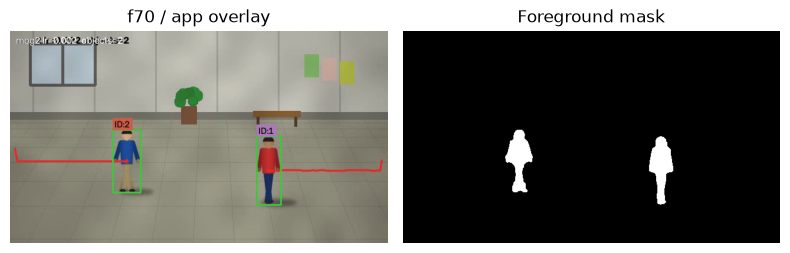

In [7]:
analyzer=VideoAnalyzer(motion=replace(params))
stream=evaluate.read_frames(video)
try:
    for index in range(71):
        current_frame=next(stream)
        result=analyzer.process(current_frame)
finally:
    stream.close()
np.testing.assert_array_equal(result.raw_mask,raw)
np.testing.assert_array_equal(result.mask,cleaned)
assert [d.bbox for d in result.detections]==[d.bbox for d in detections]
print('FrameResult.index:',result.index,'검출 수:',len(result.detections),
      '이번에 보이는 Track:',len(result.tracks),'coasting:',len(result.coasting))
table(['ID','중심','missed','hits','age','궤적 길이','최근 궤적 5점'],snapshot(result.tracks))
show_images([('f70 / app overlay',analyzer.draw(current_frame,result)),('Foreground mask',result.mask)],2)

## 7. 실제 영상 전체에서 검출·추적·평가 분리하기

고정된 test 영상 5개를 같은 MOG2 설정으로 처음부터 읽는다. 검출 목록만 보관해 여러 추적기가
**동일한 검출 입력**을 사용하게 한다. `compute_hist=True`는 색 규칙 비교용 정보를 덧붙이고 박스는 바꾸지 않는다.
정답은 `evaluate_tracking`에만 들어가며 검출·추적에는 들어가지 않는다.

저장 결과에는 입력 해시가 없으므로 과거 입력의 동일성을 소급 증명할 수는 없다.
현재 파일로 기본 표·이벤트·객체별 지표가 재현되는지 대조한다. 기존 결과와 실험 파일은 덮어쓰지 않는다.

In [8]:
criteria={'match_iou':evaluate.MATCH_IOU,'switch_persist':evaluate.SWITCH_PERSIST,
          'fail_frames':evaluate.FAIL_FRAMES,'visible':evaluate.VISIBLE,'merge_cover':evaluate.MERGE_COVER}
assert criteria==saved['criteria']
detection_cache={}
for scenario in experiments.TRACK_SCENARIOS:
    gt=synthetic.load_gt(scenario,'test')
    sequence=evaluate.detect_video(root/'data/synthetic'/gt['video'],replace(params,compute_hist=True))
    assert len(sequence)==gt['frames']
    detection_cache[scenario]=(gt,sequence)
    print(scenario,':',len(sequence),'frames')
fresh_table,fresh_logs,full=experiments.tracking_table(detection_cache)
# JSON 왕복으로 튜플을 저장 형식인 리스트로 맞춰 내용 자체를 비교한다.
assert json.loads(json.dumps(fresh_table))==saved['table']
for scenario,metrics in full.items():
    assert json.loads(json.dumps(metrics['events']))==saved['events'][scenario]
    assert json.loads(json.dumps(metrics['objects']))==saved['objects'][scenario]
rows=[]
for metrics in fresh_table:
    rows.append([metrics['name'],metrics['tests'],metrics['switch_events'],metrics['switches'],
                 metrics['fail_events'],metrics['fails'],round(metrics['coverage'],3),round(metrics['retention'],3)])
table(['조건','이벤트 수','전환 발생 이벤트','전환 횟수','실패 발생 이벤트','실패 횟수','coverage','retention'],rows)

single : 776 frames


crossing : 895 frames


crossing_same : 895 frames


pause : 897 frames


lighting : 845 frames


조건 | 이벤트 수 | 전환 발생 이벤트 | 전환 횟수 | 실패 발생 이벤트 | 실패 횟수 | coverage | retention
--- | --- | --- | --- | --- | --- | --- | ---
단일 객체 이동 | 10 | 0 | 0 | 0 | 0 | 1.0 | 1.0
두 객체 겹침 | 10 | 8 | 16 | 1 | 1 | 0.754 | 0.191
객체 일시 정지 | 5 | 2 | 2 | 2 | 2 | 0.819 | 0.431
조명 변화 | 5 | 1 | 2 | 2 | 3 | 0.92 | 0.788

## 8. 평가 숫자 읽기: 병합·미검출·ID 전환

정답 A/B와 추적 ID 1/2는 다른 이름 공간이다. 정답과 트랙 박스를 일대일로 대응한다.
하나의 박스가 정답 둘을 각각 50% 이상 덮으면 `MERGED=-1`로 표시한다.
이 구간은 누구의 ID인지 판단을 보류하고 미검출 실패로도 세지 않는다. **올바른 개별 추적이라는 뜻은 아니다.**
coverage에서는 이런 병합을 개별 대응으로 세지 않는다.

다른 ID가 5회 관측되어야 전환을 확정한다. 중간의 None·MERGED는 후보 횟수를 세지도 끊지도 않는다.
따라서 '연속한 영상 5프레임'이라는 설명은 이 구현과 다르다.
가시율 50% 이상인데 짝이 없는 상태가 연속 10프레임이면 추적 실패다. 가림은 이 구간을 끊는다.
전환 발생 **이벤트 수**와 객체별 전환 **횟수**도 구분해야 한다.

frame | 관측 ID (None=없음,-1=병합) | 그 시점의 확정 ID
--- | --- | ---
0 | 1 | None
1 | 1 | None
2 | 1 | None
3 | 1 | None
4 | 1 | 1
5 | 2 | 1
6 | 2 | 1
7 | -1 | 1
8 | None | 1
9 | 2 | 1
10 | 2 | 1
11 | 2 | 2

전환 시작 프레임,이전 ID,새 ID: [(5, 1, 2)]
9프레임 미검출: []
10프레임 미검출: [(0, 9)]
정답 A의 전환: [(104, 2, 1), (226, 1, 2), (341, 2, 3)]


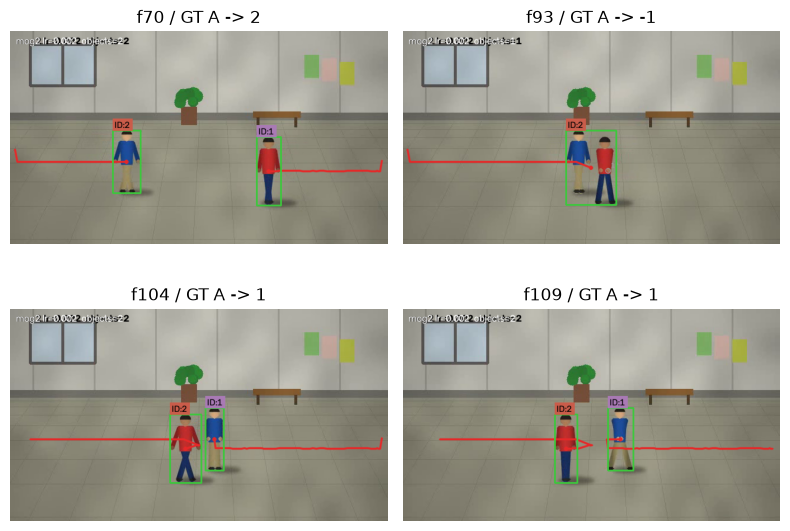

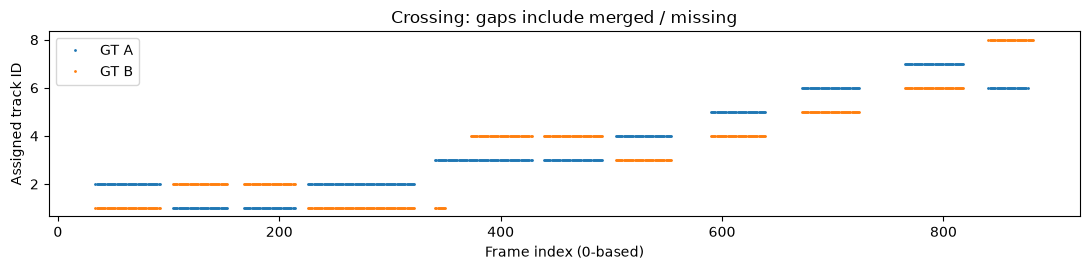

In [9]:
example=[1]*5+[2,2,evaluate.MERGED,None,2,2,2]
switches,established=evaluate.stable_switches(example)
table(['frame','관측 ID (None=없음,-1=병합)','그 시점의 확정 ID'],zip(range(len(example)),example,established))
print('전환 시작 프레임,이전 ID,새 ID:',switches)
assert switches==[(5,1,2)]
print('9프레임 미검출:',evaluate.failure_runs([None]*9,[1.0]*9))
print('10프레임 미검출:',evaluate.failure_runs([None]*10,[1.0]*10))
gt,sequence=detection_cache['crossing']
outputs=evaluate.track_detections(sequence,tracker.Tracker())
identities,visibility=evaluate.sequences(gt,outputs)
summary=full['crossing']
first_switch,_=evaluate.stable_switches(identities['A'])
print('정답 A의 전환:',first_switch[:3])
first_merged=identities['A'].index(evaluate.MERGED)
center=first_switch[0][0]
samples=sorted(set([70,first_merged,center,center+5]))
panels=[]
replay=VideoAnalyzer(motion=replace(params))
for index,photo in enumerate(evaluate.read_frames(video)):
    state=replay.process(photo)
    if index in samples:
        panels.append((f'f{index} / GT A -> {identities["A"][index]}',replay.draw(photo,state)))
    if index>=max(samples):
        break
show_images(panels,2)
fig,axis=plt.subplots(figsize=(11,2.8))
for name in ['A','B']:
    values=[]
    for value in identities[name]:
        values.append(np.nan if value is None or value==evaluate.MERGED else value)
    axis.plot(values,'.',markersize=2,label='GT '+name)
axis.set(xlabel='Frame index (0-based)',ylabel='Assigned track ID',title='Crossing: gaps include merged / missing')
axis.legend()
fig.tight_layout()
display(fig)
plt.close(fig)

정지·조명 영상도 같은 판정으로 본다. 아래는 각 영상에서 정답 A의 **첫 추적 실패 구간**을 고르고,
그 시작 직전과 10번째 미검출 프레임을 표시한다. 실패를 잘 보이게 파라미터나 입력을 바꾸지 않는다.
초록 박스는 검출 기반 추적, 청록 박스는 검증용 정답이다. 정답이 있어도 전경 검출이 없거나
사람이 아닌 영역이 큰 박스로 잡힐 수 있다. 마스크와 장면을 함께 읽는다.

pause 첫 실패 구간: (373, 408) 총 36 frames


lighting 첫 실패 구간: (127, 137) 총 11 frames


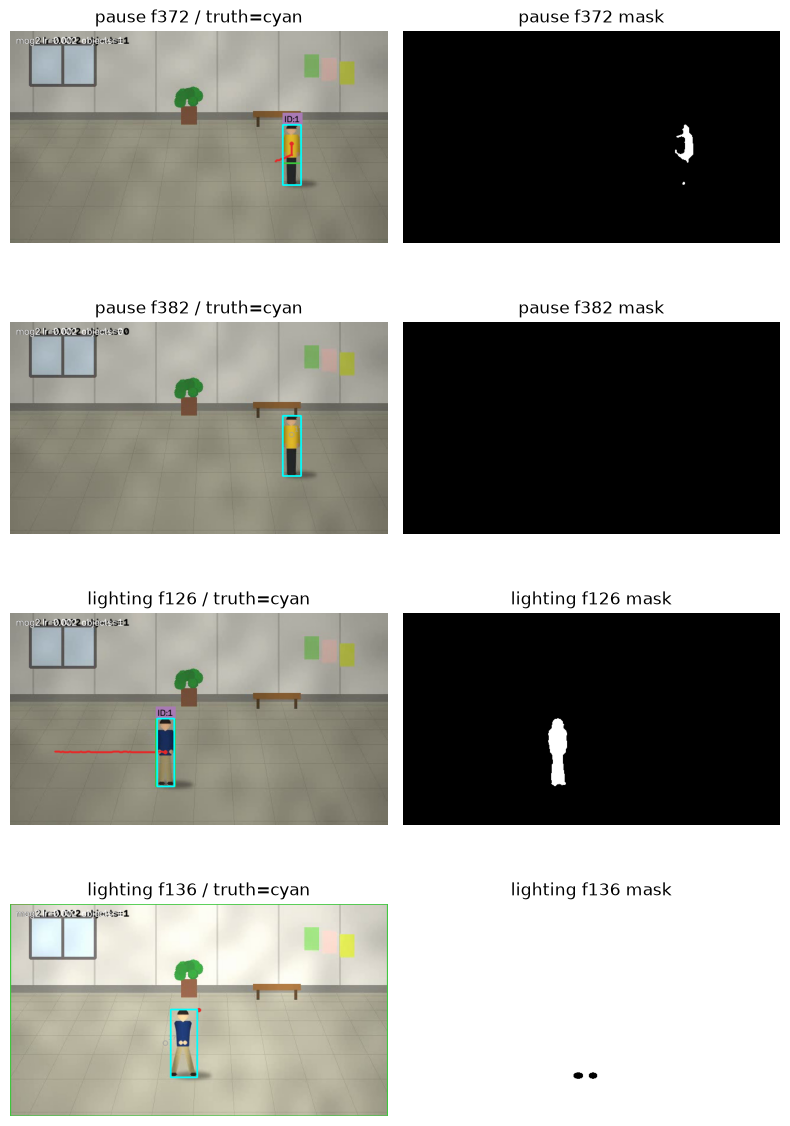

In [10]:
panels=[]
for scenario in ['pause','lighting']:
    scenario_gt,scenario_detections=detection_cache[scenario]
    scenario_outputs=evaluate.track_detections(scenario_detections,tracker.Tracker())
    scenario_ids,scenario_vis=evaluate.sequences(scenario_gt,scenario_outputs)
    start,end=evaluate.failure_runs(scenario_ids['A'],scenario_vis['A'])[0]
    print(scenario,'첫 실패 구간:',(start,end),'총',end-start+1,'frames')
    picks=[max(0,start-1),start+9]
    replay=VideoAnalyzer(motion=replace(params))
    for index,photo in enumerate(evaluate.read_frames(root/'data/synthetic'/scenario_gt['video'])):
        state=replay.process(photo)
        if index in picks:
            view=replay.draw(photo,state)
            for obj in scenario_gt['gt'][index]:
                if obj['id']=='A' and obj.get('bbox'):
                    x,y,w,h=map(int,obj['bbox'])
                    cv2.rectangle(view,(x,y),(x+w,y+h),(255,255,0),2)
            panels.append((f'{scenario} f{index} / truth=cyan',view))
            panels.append((f'{scenario} f{index} mask',state.mask))
        if index>=max(picks):
            break
show_images(panels,2)

## 9. 규칙과 파라미터: 바뀌는 단계·비교 조건

| 설정 | 바뀌는 곳 | 주의점 |
| --- | --- | --- |
| learning_rate / 앱 [ ] | 다음 프레임부터 배경 갱신 | 과거 배경을 초기화하지 않는다 |
| min_area / 모폴로지 커널 | 검출 박스 수·크기 | 추적기만 고쳐도 합쳐진 두 검출이 분리되지는 않는다 |
| max_distance | 매칭 허용 거리 px | 처리 해상도·프레임 간 이동에 의존한다 |
| max_missed | 추적 ID 보존 기간 frames | 큰 값은 사라진 객체를 오래 남긴다 |
| Hungarian / IoU / Kalman | 할당 / 비용 / 예측 | 보너스이며 검출 입력은 같다 |
| ratio / min_inliers | 등록 물체 매칭 | 사람 Track ID 매칭과 별개다 |

아래는 기존 **test 민감도 실험**을 같은 범위로 재현한다. test 결과에서 새 최적값을 고르지 않는다.
기존 dev 선택 과정·배경 모델 전체 비교·특징점 연속 곡선·속도 벤치마크는 여기서 재실행하지 않는다.
그 자료는 [기존 보고서](../REPORT.md)에 별도 실험으로 남아 있다.

In [11]:
variants=experiments.variant_experiment(detection_cache)
assert json.loads(json.dumps(variants))==saved['variants']['test']
rows=[]
for name,variant in variants.items():
    scenarios=variant['scenarios']
    rows.append([name,scenarios['crossing']['switches'],scenarios['crossing_same']['switches'],
                 scenarios['pause']['fails'],scenarios['lighting']['fails']])
table(['추적 규칙','다른 옷 교차 전환 횟수','같은 옷 교차 전환 횟수','정지 실패 횟수','조명 실패 횟수'],rows)
sensitivity=[]
for name,values in [('max_distance',[20,30,45,60,90,120,160]),('max_missed',[5,10,20,40,80,160])]:
    sweep=experiments.param_sweep(detection_cache,name,values)
    assert json.loads(json.dumps(sweep))==saved['sweeps'][name+'|test']
    for entry in sweep:
        sensitivity.append([name,entry['value'],entry['crossing']['switches'],entry['crossing_same']['switches'],
                            entry['single']['false_ids'],entry['pause']['fails']])
table(['설정','값','교차 전환','같은 옷 교차 전환','단일 영상 오검출 ID','정지 실패'],sensitivity)

추적 규칙 | 다른 옷 교차 전환 횟수 | 같은 옷 교차 전환 횟수 | 정지 실패 횟수 | 조명 실패 횟수
--- | --- | --- | --- | ---
baseline | 16 | 17 | 2 | 3
hungarian | 17 | 17 | 2 | 3
iou | 18 | 19 | 2 | 3
kalman | 7 | 9 | 2 | 3
kalman_hungarian | 8 | 10 | 2 | 3
appearance | 8 | 17 | 2 | 3
kalman_appearance | 8 | 10 | 2 | 3
all_rules | 8 | 11 | 2 | 3

설정 | 값 | 교차 전환 | 같은 옷 교차 전환 | 단일 영상 오검출 ID | 정지 실패
--- | --- | --- | --- | --- | ---
max_distance | 20 | 18 | 19 | 0 | 2
max_distance | 30 | 19 | 21 | 0 | 2
max_distance | 45 | 16 | 17 | 0 | 2
max_distance | 60 | 16 | 17 | 0 | 2
max_distance | 90 | 15 | 17 | 0 | 2
max_distance | 120 | 15 | 17 | 0 | 2
max_distance | 160 | 15 | 17 | 0 | 2
max_missed | 5 | 17 | 18 | 0 | 2
max_missed | 10 | 16 | 17 | 0 | 2
max_missed | 20 | 16 | 17 | 0 | 2
max_missed | 40 | 13 | 14 | 0 | 2
max_missed | 80 | 13 | 15 | 0 | 2
max_missed | 160 | 14 | 15 | 0 | 2

## 10. 등록 물체: 특징점 → 기술자 거리 → 비율 검정 → RANSAC

표지를 등록하는 것은 예제 이미지에서 특징을 추출하는 일이며 분류기를 학습하는 일이 아니다.
ORB 기술자는 `(특징점 수,32)` uint8(256비트)이며 **해밍 거리**로 비교한다.
SIFT는 `(특징점 수,128)` 실수 기술자와 L2 거리를 쓴다.
`knnMatch(k=2)`는 등록 기술자마다 장면의 가까운 후보 두 개를 주는 중첩 목록이다.
`1등 거리 < 0.75*2등 거리`인 매칭만 남겨 애매함을 줄인다.
RANSAC은 이 점 쌍으로 같은 투시 변환을 지지하는 inlier를 고른다. 확률이나 정답 인증이 아니다.

기존 target_test f120에서 처음 이 계산을 펼치고 기존 `TargetMatcher.match`와 대조한다.
`found` 조건은 inlier 수·볼록성·투영 면적이다. 정답 위치 오차는 별도 평가다.

등록 기술자: (340, 32) uint8 장면 기술자: (915, 32) uint8


등록 번호 | 장면 1등 번호 | 1등 해밍 거리 | 2등 거리 | 비율 통과
--- | --- | --- | --- | ---
0 | 346 | 75 | 79.0 | False
1 | 841 | 62 | 64.0 | False
2 | 503 | 65 | 72.0 | False
3 | 309 | 70 | 72.0 | False
4 | 856 | 82 | 86.0 | False
5 | 746 | 78 | 78.0 | False
6 | 490 | 65 | 71.0 | False
7 | 778 | 76 | 79.0 | False

비율 통과: 28 inlier: 25 found: True


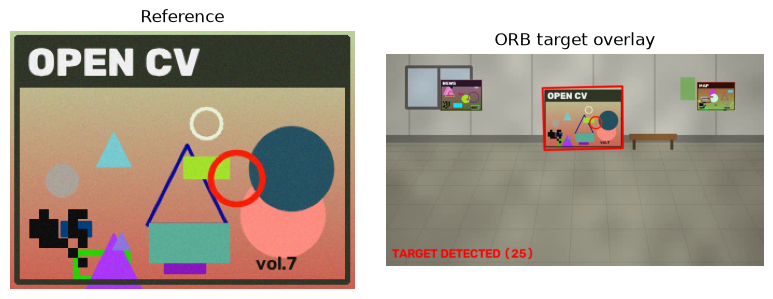

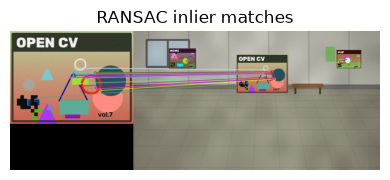

정답 네 모서리 평균 오차 px: 2.391167866412739 (TARGET DETECTED 표시와 별도 지표)


In [12]:
texture=imread(root/'data/target/target.png')
target_stream=evaluate.read_frames(root/'data/synthetic/target_test.mp4')
try:
    for index in range(121):
        target_frame=next(target_stream)
finally:
    target_stream.close()
matcher=features.TargetMatcher(texture,'orb')
scene_gray=cv2.cvtColor(target_frame,cv2.COLOR_BGR2GRAY)
keypoints,descriptors=matcher.detector.detectAndCompute(scene_gray,None)
pairs=matcher.matcher.knnMatch(matcher.ref_des,descriptors,k=2)
good=[]
ratio_rows=[]
for number,pair in enumerate(pairs):
    if len(pair)!=2:
        continue
    first,second=pair
    accepted=first.distance<matcher.ratio*second.distance
    if number<8:
        # XOR 뒤 켜진 비트 수가 실제 해밍 거리인지 한 후보씩 확인한다.
        xor=np.bitwise_xor(matcher.ref_des[first.queryIdx],descriptors[first.trainIdx])
        manual_hamming=int(np.unpackbits(xor).sum())
        assert manual_hamming==first.distance
        ratio_rows.append([first.queryIdx,first.trainIdx,manual_hamming,second.distance,accepted])
    if accepted:
        good.append(first)
print('등록 기술자:',matcher.ref_des.shape,matcher.ref_des.dtype,
      '장면 기술자:',descriptors.shape,descriptors.dtype)
table(['등록 번호','장면 1등 번호','1등 해밍 거리','2등 거리','비율 통과'],ratio_rows)
ref_points=np.float32([matcher.ref_kp[m.queryIdx].pt for m in good])
scene_points=np.float32([keypoints[m.trainIdx].pt for m in good])
cv2.setRNGSeed(0)
H,inlier_mask=cv2.findHomography(ref_points,scene_points,cv2.RANSAC,matcher.ransac_thresh)
inlier_mask=inlier_mask.ravel().astype(bool)
if inlier_mask.sum()>=8:
    refined,_=cv2.findHomography(ref_points[inlier_mask],scene_points[inlier_mask],0)
    if refined is not None:
        H=refined
corners=cv2.perspectiveTransform(matcher.ref_corners[None],H)[0]
cv2.setRNGSeed(0)
matched=matcher.match(target_frame)
assert matched.n_good==len(good) and matched.n_inliers==int(inlier_mask.sum())
np.testing.assert_allclose(H,matched.H,atol=1e-8)
np.testing.assert_allclose(corners,matched.corners,atol=1e-5)
print('비율 통과:',len(good),'inlier:',matched.n_inliers,'found:',matched.found)
lines=cv2.drawMatches(texture,matcher.ref_kp,target_frame,keypoints,good,None,
                      matchesMask=inlier_mask.astype(int).tolist(),flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
show_images([('Reference',texture),('ORB target overlay',features.draw_match(target_frame.copy(),matched))],2)
show_images([('RANSAC inlier matches',lines)],1)
target_gt=synthetic.load_gt('target','test')
truth=next(o for o in target_gt['gt'][120] if o['id']=='T')
error=np.linalg.norm(matched.corners-np.array(truth['corners']),axis=1).mean()
print('정답 네 모서리 평균 오차 px:',error,'(TARGET DETECTED 표시와 별도 지표)')

## 11. 특징점 성공·실패와 일반화의 범위

기존 조건별 실험을 ORB/SIFT 각각 10회, 기존 생성 조건 그대로 다시 계산한다.
표의 검출률은 단순 found가 아니라 정답 모서리와의 오차 등을 포함한 `score_view` 판정이다.
match_rate는 올바른 대응 수/등록 특징점 수, precision은 올바른 대응 수/비율 통과 수다.
RANSAC inlier와 정답으로 확인한 올바른 대응도 구분한다.
등록 물체와 비슷한 다른 표지의 found 비율도 기존 조건으로 대조한다.

In [13]:
condition_results=experiments.feature_conditions(texture,trials=10)
generalization=experiments.generalization(texture,trials=10)
# 재실행 환경의 작은 실수 오차만 허용하고 표본·조건은 그대로 비교한다.
def compare_values(current,old):
    if isinstance(current,dict):
        assert current.keys()==old.keys()
        for key in current:
            compare_values(current[key],old[key])
    elif isinstance(current,list):
        assert len(current)==len(old)
        for a,b in zip(current,old):
            compare_values(a,b)
    elif isinstance(current,(float,int)):
        np.testing.assert_allclose(current,old,atol=1e-8,rtol=1e-8)
    else:
        assert current==old
compare_values(condition_results,saved['features']['table'])
compare_values(generalization,saved['features']['generalization'])
rows=[]
for method,conditions in condition_results.items():
    for condition in conditions:
        rows.append([method,condition['condition'],round(condition['n_good'],1),round(condition['n_inliers'],1),
                     round(condition['match_rate'],3),round(condition['precision'],3),condition['found_rate']])
table(['방법','조건','비율 통과 평균','inlier 평균','match_rate','precision','정답 위치 검출률'],rows)
rows=[]
for method,cases in generalization.items():
    for case in cases:
        rows.append([method,case['case'],case['found_rate']])
table(['방법','물체 변형','found 비율 (정답 위치 검출률과 구별)'],rows)

방법 | 조건 | 비율 통과 평균 | inlier 평균 | match_rate | precision | 정답 위치 검출률
--- | --- | --- | --- | --- | --- | ---
orb | 정면 | 45.8 | 44.4 | 0.131 | 0.969 | 1.0
orb | 30도 회전 (평면 안) | 39.9 | 38.8 | 0.114 | 0.974 | 1.0
orb | 60도 회전 (평면 안) | 38.7 | 37.6 | 0.11 | 0.97 | 1.0
orb | 30도 기울임 (3D) | 37.4 | 36.9 | 0.109 | 0.987 | 1.0
orb | 60도 기울임 (3D) | 1.9 | 0.4 | 0.001 | 0.125 | 0.0
orb | 30% 가림 | 44.4 | 42.3 | 0.126 | 0.969 | 0.6
orb | 50% 가림 | 17.1 | 15.9 | 0.046 | 0.877 | 0.4
sift | 정면 | 82.3 | 67.9 | 0.338 | 0.831 | 1.0
sift | 30도 회전 (평면 안) | 81.7 | 66.8 | 0.332 | 0.822 | 1.0
sift | 60도 회전 (평면 안) | 78.6 | 64.3 | 0.32 | 0.823 | 1.0
sift | 30도 기울임 (3D) | 72.7 | 61.3 | 0.305 | 0.847 | 1.0
sift | 60도 기울임 (3D) | 16.5 | 6.3 | 0.022 | 0.289 | 0.0
sift | 30% 가림 | 59.4 | 43.4 | 0.214 | 0.718 | 1.0
sift | 50% 가림 | 48.4 | 33.3 | 0.165 | 0.663 | 1.0

방법 | 물체 변형 | found 비율 (정답 위치 검출률과 구별)
--- | --- | ---
orb | 등록 물체 그대로 | 1.0
orb | 같은 시리즈 다른 권 | 0.0
orb | 무관한 표지 | 0.0
orb | 색 반전 (음화) | 0.0
orb | 윤곽선 그림 | 0.0
sift | 등록 물체 그대로 | 1.0
sift | 같은 시리즈 다른 권 | 1.0
sift | 무관한 표지 | 0.0
sift | 색 반전 (음화) | 0.0
sift | 윤곽선 그림 | 0.0

색·운동 예측·할당 규칙이 일부 조건을 개선해도 모든 교차와 조명·정지 문제를 해결하지는 않는다.
정보가 가려지면 같은 관측에 여러 실제 동선이 대응할 수 있다. 외형 외의 추가 센서·다른 시점도
도움이 될 수 있으므로 외형만이 유일한 해법이라고 단정하지 않는다.
학습 기반 검출·재식별·특징 표현은 다음 비교 가설이지만 여기서 그 성능을 측정한 것은 아니다.

## 12. 보너스: 바뀌는 계산만 연결하기

Hungarian은 비용 합을 최소화한다. 탐욕보다 낮은 합이라고 실제 신원이 맞다는 보장은 없다.
IoU는 박스 겹침을 보며, 칼만은 `[x,y,vx,vy]` 상태를 예측한다. 병합된 검출을 둘로 분리하지는 않는다.
침입 구역은 Track 중심이 들어왔는지 검사하며 ID 오류도 로그에 전파된다.
아래 작은 입력은 실제 영상 실험과 구별되는 설명용 계산이다.

In [14]:
toy_cost=np.array([[1.,2.],[2.,100.]])
rows=[]
for method in ['greedy','hungarian']:
    assignment,_,_=gated_assignment(toy_cost,100.,method)
    total=sum(toy_cost[i,j] for i,j in assignment)
    rows.append([method,assignment,total])
table(['할당 방법','짝 (행,열)','비용 합'],rows)
print('IoU: 10×10 박스를 가로로 5px 이동:',tracker.iou((0,0,10,10),(5,0,10,10)))
kalman=tracker.make_kalman(10,20)
kalman.statePost=np.array([[10.],[20.],[3.],[-1.]])
predicted=kalman.transitionMatrix@kalman.statePost
np.testing.assert_allclose(predicted,kalman.predict())
print('한 프레임 예측 [x,y,vx,vy]:',predicted.ravel())

할당 방법 | 짝 (행,열) | 비용 합
--- | --- | ---
greedy | [(0, 0), (1, 1)] | 101.0
hungarian | [(0, 1), (1, 0)] | 4.0

IoU: 10×10 박스를 가로로 5px 이동: 0.3333333333333333
한 프레임 예측 [x,y,vx,vy]: [13. 19.  3. -1.]


## 13. 학습에서 친구 시연으로

**학습:** 1~6절에서 한 프레임의 입력·배열·상태를 따라간다 → 7~9절에서 ID 전환과 평가 숫자를 읽는다
→ 10~11절에서 등록 물체의 별도 매칭 흐름을 배운다 → 12절 보너스를 비교한다.
시간에 따른 교차를 반복해서 볼 때는 [HTML 재생 위젯](../study/a3-2.html)을 함께 사용한다.
HTML의 JS 재생과 노트북의 실제 Python 실행은 구별한다.

A3-2 폴더에서 기본 추적을 먼저 시연한다. 등록 물체를 끄면 검출·추적 설명에 집중할 수 있다.

```powershell
uv run python -m src.app --source data/synthetic/crossing_test.mp4 --target ''
```

PowerShell의 빈 문자열 인자 전달이 어려우면 `--target=`으로 지정한다.
1. 초록 박스·ID·빨간 궤적·회색 `n?`를 설명한다. 배경 모델이 빈 배경을 먼저 읽는 1초도 본다.
2. 첫 교차가 가까워지면 `p` 일시정지, `n`으로 한 프레임씩 이동한다. 두 박스가 하나로 붙는 지점을 본다.
3. `m`으로 마스크를 열고, 병합과 ID 바뀜을 구별한다. `s`로 주석·원본·마스크를 저장하고 `q`로 끝낸다.
4. 아래 pause 영상에서는 사람이 멈추어도 여전히 사람인데 왜 전경에서 사라지는지 설명한다.
   `[`/`]`는 다음 프레임부터 학습률을 바꾸며 기존 배경은 남는다.
   공정하게 비교하려면 앱을 새로 실행해 같은 영상 시작점부터 처리한다.
5. target 영상에서는 `TARGET DETECTED`와 사람의 Track ID가 별도 처리임을 설명한다.
   found 표시만 보지 말고 정답 위치 평가와 차이도 10~11절에서 보여준다.

```powershell
uv run python -m src.app --source data/synthetic/pause_test.mp4 --target=
uv run python -m src.app --source data/synthetic/lighting_test.mp4 --target=
uv run python -m src.app --source data/synthetic/target_test.mp4 --feature orb
uv run python -m src.app --source data/synthetic/target_test.mp4 --feature sift
uv run python -m src.app --kalman --matcher hungarian --target=
```

마우스로 구역을 끌어 지정하고 `c`로 지운다. `--width`를 바꾸면 거리·면적의 픽셀 단위 의미도 달라진다.
화면 FPS는 표시·대기를 포함하고 `proc`는 처리 속도다. 노트북 계산 시간과 같은 수치로 비교하지 않는다.
창이 없는 환경에서는 다음 명령으로 주석 영상과 스냅샷을 저장할 수 있다.

```powershell
uv run python -m src.app --no-gui --source data/synthetic/crossing_test.mp4 --target= --out outputs/cli --snap-every 90
```

**확인 질문:** 같은 프레임만 새 배경 모델에 넣으면 왜 결과가 다른가? visible과 alive는 어떻게 다른가?
병합을 실패 횟수에서 뺐는데 coverage가 낮아질 수 있는가? 거리 임계값을 키워도 사람 신원을 알 수 없는 이유는?
비율 검정 통과 수·RANSAC inlier 수·정답 위치 검출률은 각각 무엇인가?